# HW1 Part C - Analysis and Interpretation

Using the same SIR model (forward Euler) and the Part B values.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def sir_model(S0, I0, R0, beta, gamma, days, dt=0.1):
    # number of steps
    n = int(days / dt)

    t = np.zeros(n + 1)
    S = np.zeros(n + 1)
    I = np.zeros(n + 1)
    R = np.zeros(n + 1)

    # starting values
    S[0] = S0
    I[0] = I0
    R[0] = R0

    for k in range(n):
        dS = -beta * S[k] * I[k]
        dI = beta * S[k] * I[k] - gamma * I[k]
        dR = gamma * I[k]

        S[k + 1] = S[k] + dt * dS
        I[k + 1] = I[k] + dt * dI
        R[k + 1] = R[k] + dt * dR
        t[k + 1] = t[k] + dt

    return t, S, I, R

In [3]:
N = 2000
beta = 0.125e-3
gamma = 0.1

t, S, I, R = sir_model(1995, 5, 0, beta, gamma, 160)

## i. Infection peak

Peak day: 42.7
Infected at peak: 470
S at peak: 800
R at peak: 730
gamma/beta = 800.0


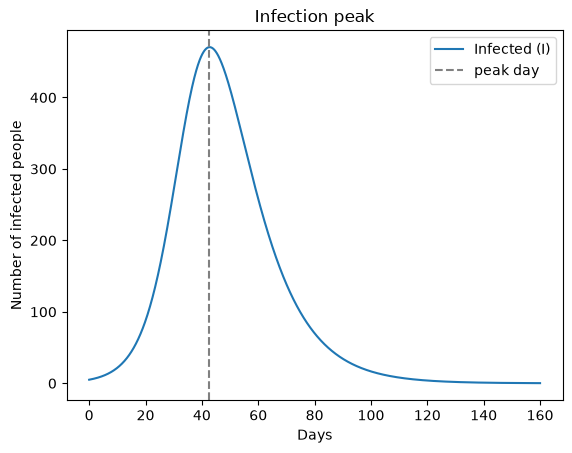

In [4]:
peak_index = np.argmax(I)
peak_day = t[peak_index]
peak_I = I[peak_index]

print('Peak day:', round(peak_day, 1))
print('Infected at peak:', round(peak_I))
print('S at peak:', round(S[peak_index]))
print('R at peak:', round(R[peak_index]))
print('gamma/beta =', gamma / beta)

plt.plot(t, I, label='Infected (I)')
plt.axvline(peak_day, color='gray', linestyle='--', label='peak day')
plt.xlabel('Days')
plt.ylabel('Number of infected people')
plt.title('Infection peak')
plt.legend()
plt.show()

**Discussion:**

The number of infected people peaks around day 43 with about 470 people infected at the same time.

The peak happens when new infections per day equal recoveries per day:

beta * S * I = gamma * I  ->  S = gamma / beta = 800


Factors that decide the peak:
- **beta (transmission rate):** higher beta means faster spread, so the peak is higher and earlier.
- **gamma (recovery rate):** higher gamma means people recover faster, so fewer are sick at once and the peak is lower.
- **Starting number of susceptible people / population size:** more susceptible people means more people to infect, so a bigger peak.
- **Starting number of infected (I0):** more starting infected mostly makes the peak come earlier.

In my hypothesis I guessed the peak around day 35-40. The real peak is a bit later because the early growth slows down sooner than my simple doubling estimate assumed in hypothesis.

## ii. Basic reproduction number

In [5]:
R_0 = beta * N / gamma
print('R0 =', R_0)

R0 = 2.5


**Discussion:**

R0 = (0.125e-3 * 2000) / 0.1 = 2.5

This means one infected person infects about 2.5 other people on average (when almost everyone is still susceptible). A sick person is sick for about 1/gamma = 10 days and infects about 0.25 people per day, so 0.25 * 10 = 2.5.

How R0 affects spread and control:
- If **R0 > 1**, each case leads to more than one new case, so the outbreak grows. Here R0 = 2.5 so we get a big outbreak.
- If **R0 < 1**, each case leads to less than one new case, so the disease dies out.
- A bigger R0 means a faster, larger outbreak and more people infected in total.
- To control the epidemic we need to bring R0 below 1. We can lower beta (social distancing, masks, isolation) or raise gamma (faster treatment). Vaccination also works by lowering the number of susceptible people.
- The outbreak stops growing when S drops below N/R0 = 800, which matches the peak in part i.

## iii. Epidemic dynamics

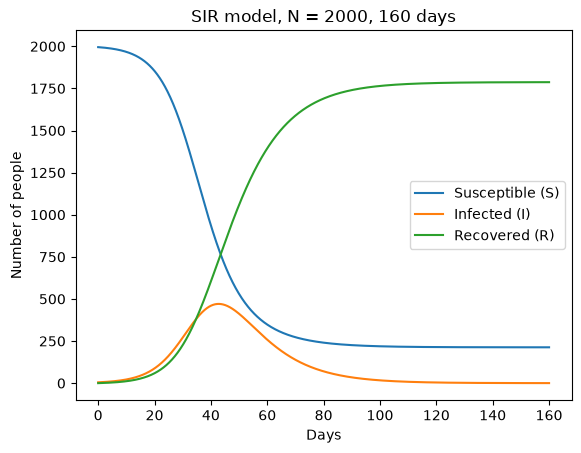

At day 160:
S = 213  (never infected)
I = 0
R = 1787
Percent never infected: 10.6 %


In [6]:
plt.plot(t, S, label='Susceptible (S)')
plt.plot(t, I, label='Infected (I)')
plt.plot(t, R, label='Recovered (R)')
plt.xlabel('Days')
plt.ylabel('Number of people')
plt.title('SIR model, N = 2000, 160 days')
plt.legend()
plt.show()

print('At day 160:')
print('S =', round(S[-1]), ' (never infected)')
print('I =', round(I[-1]))
print('R =', round(R[-1]))
print('Percent never infected:', round(100 * S[-1] / N, 1), '%')

**Discussion:**

- **S (susceptible):** stays close to original population for the first ~20 days, then drops fast between day 20 and 60, and then levels off. It never goes to zero.
- **I (infected):** starts at 5, grows slowly at first, then quickly, peaks around day 42, then goes down to almost 0 by around day 120.
- **R (recovered):** starts at 0 and goes up like an S-shape, ending around 1785.

About 213 people (around 10.6%) are never infected by the end of the simulation.

How the compartments interact:
- People only move S -> I -> R. The total S + I + R stays 2000.
- New infections need both susceptible and infected people (the beta * S * I term). 
- As more people get infected, S gets smaller, so each sick person finds fewer people to infect.
- After S drops below 800, recoveries are faster than new infections, so I goes down.
- The outbreak ends because there are not enough infected people left to keep spreading it.